In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import fsolve

In [2]:
# Parameters

asset = "MSFT"  # Microsoft
ticker = yf.Ticker(asset)                          
S0 = ticker.history(period="1d")["Close"].iloc[-1]  # Spot price in $
sigma0 = 0.6    # volatility
r= 0.03         # interest rate
q = 0           # dividend yield
print(S0)

523.0


In [3]:
expiries = ticker.options  # available maturity for the options
expiries
expiries = list(expiries)
expiries

['2026-11-13',
 '2026-11-16',
 '2026-11-18',
 '2026-11-20',
 '2026-11-27',
 '2026-12-04',
 '2026-12-11',
 '2026-12-18',
 '2026-12-24',
 '2027-01-15',
 '2027-02-19',
 '2027-03-19',
 '2027-04-16',
 '2027-06-17',
 '2027-09-17',
 '2027-12-17',
 '2028-01-21',
 '2028-06-16',
 '2028-12-15',
 '2029-01-19']

In [4]:
# For each maturity date, we add a price, strike for a call option and put option

L_call = []
L_put = []

for maturity in expiries:

    option_chain = ticker.option_chain(date=maturity)

    call = option_chain.calls
    call["Maturity"] = maturity
    L_call.append(call)

    put = option_chain.puts
    put["Maturity"] = maturity
    L_put.append(put)

df_call= pd.concat(L_call)
df_put = pd.concat(L_put)
df_call


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,Maturity
0,MSFT261113C00270000,2026-11-12 16:26:43+00:00,270.0,258.77,0.0,0.0,0.0,0.0,2.0,0,0.000010,True,REGULAR,USD,2026-11-13
1,MSFT261113C00280000,2026-11-12 15:16:26+00:00,280.0,245.25,0.0,0.0,0.0,0.0,2.0,0,0.000010,True,REGULAR,USD,2026-11-13
2,MSFT261113C00290000,2026-11-12 15:15:58+00:00,290.0,235.01,0.0,0.0,0.0,0.0,1.0,0,0.000010,True,REGULAR,USD,2026-11-13
3,MSFT261113C00325000,2026-11-12 19:44:06+00:00,325.0,198.73,0.0,0.0,0.0,0.0,154.0,0,0.000010,True,REGULAR,USD,2026-11-13
4,MSFT261113C00330000,2026-11-12 19:44:06+00:00,330.0,193.73,0.0,0.0,0.0,0.0,133.0,0,0.000010,True,REGULAR,USD,2026-11-13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,MSFT290119C00780000,2026-11-11 20:49:51+00:00,780.0,41.95,0.0,0.0,0.0,0.0,2.0,0,0.062509,False,REGULAR,USD,2029-01-19
82,MSFT290119C00790000,2026-11-12 15:52:42+00:00,790.0,41.59,0.0,0.0,0.0,0.0,1.0,0,0.062509,False,REGULAR,USD,2029-01-19
83,MSFT290119C00795000,2026-11-10 16:17:00+00:00,795.0,46.00,0.0,0.0,0.0,0.0,3.0,0,0.062509,False,REGULAR,USD,2029-01-19
84,MSFT290119C00800000,2026-11-12 20:20:55+00:00,800.0,38.90,0.0,0.0,0.0,0.0,3.0,0,0.062509,False,REGULAR,USD,2029-01-19


In [5]:
# Building the dataframes and first cleaning

columns = ["strike",'Maturity',"lastPrice","bid","ask","impliedVolatility","volume"]



df_call = df_call[columns]

df_call["mid"] = 0.5 * (df_call["bid"] + df_call["ask"])

df_call["Maturity"] = pd.to_datetime(df_call["Maturity"])

# filter

# Strike between 80% et 120%
strike_filter = (S0*0.8< df_call["strike"]) & (df_call["strike"]<S0*1.2)
df_call = df_call[strike_filter]

# maturity between today and 3 months 
maturity_filter = (df_call["Maturity"]>pd.Timestamp.today()) & (df_call["Maturity"] < pd.Timestamp.today() + pd.Timedelta(days=100))
df_call = df_call[maturity_filter]

# volume > 50
df_call = df_call[df_call["volume"]>50]

#mid price
# mid_filter = (df_call["mid"] >= 0.10)
# df_call = df_call[mid_filter]

df_call

# Put filter

df_put = df_put[columns]
df_put["mid"] = 0.5 * (df_put["bid"] + df_put["ask"])
df_put["Maturity"] = pd.to_datetime(df_put["Maturity"])



strike_filter = (S0*0.8< df_put["strike"]) & (df_put["strike"]<S0*1.2)
df_put = df_put[strike_filter]

maturity_filter = (df_put["Maturity"]>pd.Timestamp.today()) & (df_put["Maturity"] < pd.Timestamp.today() + pd.Timedelta(days=100))
df_put = df_put[maturity_filter]

# volume > 50
df_put = df_put[df_put["volume"]>50]

# mid price
mid_filter = (df_put["mid"] >= 0.10)
df_put = df_put[mid_filter]

df_call


C:\Users\antoi\AppData\Local\Temp\ipykernel_11840\31573668.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_call["mid"] = 0.5 * (df_call["bid"] + df_call["ask"])
C:\Users\antoi\AppData\Local\Temp\ipykernel_11840\31573668.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_call["Maturity"] = pd.to_datetime(df_call["Maturity"])


,strike,Maturity,lastPrice,bid,ask,impliedVolatility,volume,mid
11,520.0,2026-11-16,7.10,0.0,0.0,0.000010,251.0,0.0
12,522.5,2026-11-16,6.25,0.0,0.0,0.000010,703.0,0.0
13,525.0,2026-11-16,4.98,0.0,0.0,0.007822,1038.0,0.0
14,527.5,2026-11-16,3.72,0.0,0.0,0.015635,415.0,0.0
15,530.0,2026-11-16,2.89,0.0,0.0,0.031260,1648.0,0.0
...,...,...,...,...,...,...,...,...
58,560.0,2027-02-19,19.49,0.0,0.0,0.031260,127.0,0.0
60,570.0,2027-02-19,16.27,0.0,0.0,0.031260,105.0,0.0
64,590.0,2027-02-19,11.25,0.0,0.0,0.062509,59.0,0.0
65,595.0,2027-02-19,10.25,0.0,0.0,0.062509,209.0,0.0


In [6]:
# Price Call/Put with Black and Scholes
def black_scholes(S0,K,r,sigma,T,q,option_type="call"):

    d1= (np.log(S0/K)+(0.5*sigma**2*+r-q)*T)/(sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    if option_type == "call":
        return S0*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2) 
    
    if option_type == "put":
        return K*np.exp(-r*T)*norm.cdf(-d2)-S0*norm.cdf(-d1) 

In [7]:
option_type = "call"

In [8]:
def Newton(f,df,x0,error1,error2):
    x = x0
    while abs(f(x))>error1 or abs(x-x0)>error2:
        x0 = x
        x = x - f(x)/df(x)
    return x

In [9]:
# Function to get the determine the implied volatility
def implied_volatility(S0,K,T,r,q,market_price):
    def f(sigma):
        return black_scholes(S0,K,r,sigma,T,q,option_type)-market_price
    return fsolve(f,x0=sigma0,xtol=1e-8,maxfev=500)  

In [10]:
# For a given maturity date, we want to know the value of the implied volatility for each strike

smile = {}

for t in df_call["Maturity"].drop_duplicates():
    time_to_maturity = (t - pd.Timestamp.today()).days / 365
    L_implied_vol=[]
    L_K = []

    df_t = df_call[df_call["Maturity"]==t]

    for _,row in df_t.iterrows():
        K = row["strike"]
        market_price = row["lastPrice"]     # or  row["mid"] 

        implied_vol = float(implied_volatility(S0,K,time_to_maturity,r,q,market_price)[0])
        L_implied_vol.append(implied_vol)
        L_K.append(K)
    
    smile[t] = {"K":L_K,
                "iv":L_implied_vol}
        

C:\Users\antoi\AppData\Local\Temp\ipykernel_11840\1464899031.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(f,x0=sigma0,xtol=1e-8,maxfev=500)


In [11]:
smile

{Timestamp('2026-11-16 00:00:00'): {'K': [520.0,
   522.5,
   525.0,
   527.5,
   530.0,
   532.5,
   535.0,
   537.5,
   540.0,
   542.5,
   545.0,
   547.5,
   550.0,
   555.0,
   560.0],
  'iv': [0.35191367795352296,
   0.3857078782644312,
   0.38058195231313213,
   0.3646694958729007,
   0.36613936172525685,
   0.33926714664202,
   0.3569776280210636,
   0.3510519489996423,
   0.3489003440983422,
   0.3378955693405124,
   0.3536383799017612,
   0.350561206783367,
   0.3654290313493461,
   0.38203208631616087,
   0.36914597310372665]},
 Timestamp('2026-11-18 00:00:00'): {'K': [480.0,
   520.0,
   525.0,
   527.5,
   530.0,
   532.5,
   535.0,
   537.5,
   540.0,
   542.5,
   545.0,
   547.5,
   550.0,
   552.5,
   555.0,
   557.5,
   560.0],
  'iv': [0.01865427129444258,
   0.3738069549625196,
   0.3423762336855223,
   0.3451692973269392,
   0.35940879156848543,
   0.34347621985331794,
   0.33667949961497246,
   0.333082065553078,
   0.33970940823617973,
   0.33152265393121744,
   0

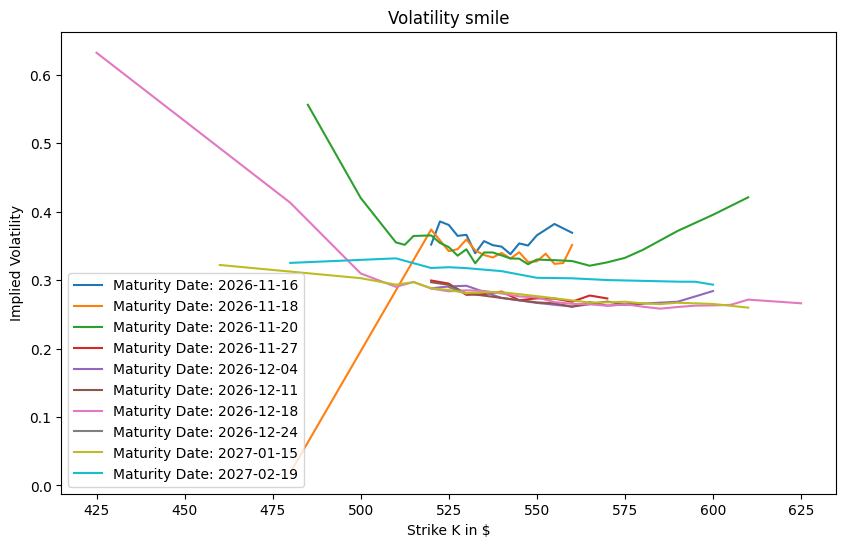

In [12]:
plt.figure(figsize=(10,6))
for t, data in smile.items():  # smile.items() renvoie couples (clé,valeur)
    plt.plot(data["K"],data["iv"],label="Maturity Date: " + str(t.date()))

plt.xlabel("Strike K in $")
plt.ylabel("Implied Volatility")
plt.title('Volatility smile')
plt.legend()
plt.show()

In [13]:
# For a given strike, we want to know the value of the implied volatility for each maturity

term_structure = {}
df_call = df_call.sort_values(by="strike",ascending=True)
for K in df_call["strike"].drop_duplicates():
    L_implied_vol=[]
    L_T = []

    df_K = df_call[df_call["strike"]==K]

    for _,row in df_K.iterrows():
        T = row["Maturity"]
        time_to_maturity = (T - pd.Timestamp.today()).days / 365
        market_price = row["lastPrice"]  # or row["mid"]

        implied_vol = float(implied_volatility(S0,K,time_to_maturity,r,q,market_price)[0])  # [0]
        
        L_implied_vol.append(implied_vol)
        #implied_vol = row["impliedVolatility"]
        L_T.append(T)
    
    term_structure[K] = {"T":L_T,
                "iv":L_implied_vol}
print(term_structure)

C:\Users\antoi\AppData\Local\Temp\ipykernel_11840\1464899031.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(f,x0=sigma0,xtol=1e-8,maxfev=500)


{425.0: {'T': [Timestamp('2026-12-18 00:00:00')], 'iv': [0.6321692181834633]}, 460.0: {'T': [Timestamp('2027-01-15 00:00:00')], 'iv': [0.32210621526142286]}, 480.0: {'T': [Timestamp('2026-11-18 00:00:00'), Timestamp('2026-12-18 00:00:00'), Timestamp('2027-02-19 00:00:00')], 'iv': [0.01865427129444258, 0.41306412487154487, 0.3251414162039827]}, 485.0: {'T': [Timestamp('2026-11-20 00:00:00')], 'iv': [0.5560899243336649]}, 500.0: {'T': [Timestamp('2026-11-20 00:00:00'), Timestamp('2026-12-18 00:00:00'), Timestamp('2027-01-15 00:00:00')], 'iv': [0.42002912833172024, 0.30973060856234297, 0.3028401023588288]}, 510.0: {'T': [Timestamp('2027-01-15 00:00:00'), Timestamp('2026-11-20 00:00:00'), Timestamp('2026-12-18 00:00:00'), Timestamp('2027-02-19 00:00:00')], 'iv': [0.2933472824048972, 0.35506212054504277, 0.29016484498091927, 0.33178359280069586]}, 512.5: {'T': [Timestamp('2026-11-20 00:00:00')], 'iv': [0.35155738377595913]}, 515.0: {'T': [Timestamp('2026-12-18 00:00:00'), Timestamp('2026-11

In [14]:
term_structure

{425.0: {'T': [Timestamp('2026-12-18 00:00:00')], 'iv': [0.6321692181834633]},
 460.0: {'T': [Timestamp('2027-01-15 00:00:00')], 'iv': [0.32210621526142286]},
 480.0: {'T': [Timestamp('2026-11-18 00:00:00'),
   Timestamp('2026-12-18 00:00:00'),
   Timestamp('2027-02-19 00:00:00')],
  'iv': [0.01865427129444258, 0.41306412487154487, 0.3251414162039827]},
 485.0: {'T': [Timestamp('2026-11-20 00:00:00')], 'iv': [0.5560899243336649]},
 500.0: {'T': [Timestamp('2026-11-20 00:00:00'),
   Timestamp('2026-12-18 00:00:00'),
   Timestamp('2027-01-15 00:00:00')],
  'iv': [0.42002912833172024, 0.30973060856234297, 0.3028401023588288]},
 510.0: {'T': [Timestamp('2027-01-15 00:00:00'),
   Timestamp('2026-11-20 00:00:00'),
   Timestamp('2026-12-18 00:00:00'),
   Timestamp('2027-02-19 00:00:00')],
  'iv': [0.2933472824048972,
   0.35506212054504277,
   0.29016484498091927,
   0.33178359280069586]},
 512.5: {'T': [Timestamp('2026-11-20 00:00:00')], 'iv': [0.35155738377595913]},
 515.0: {'T': [Timestamp

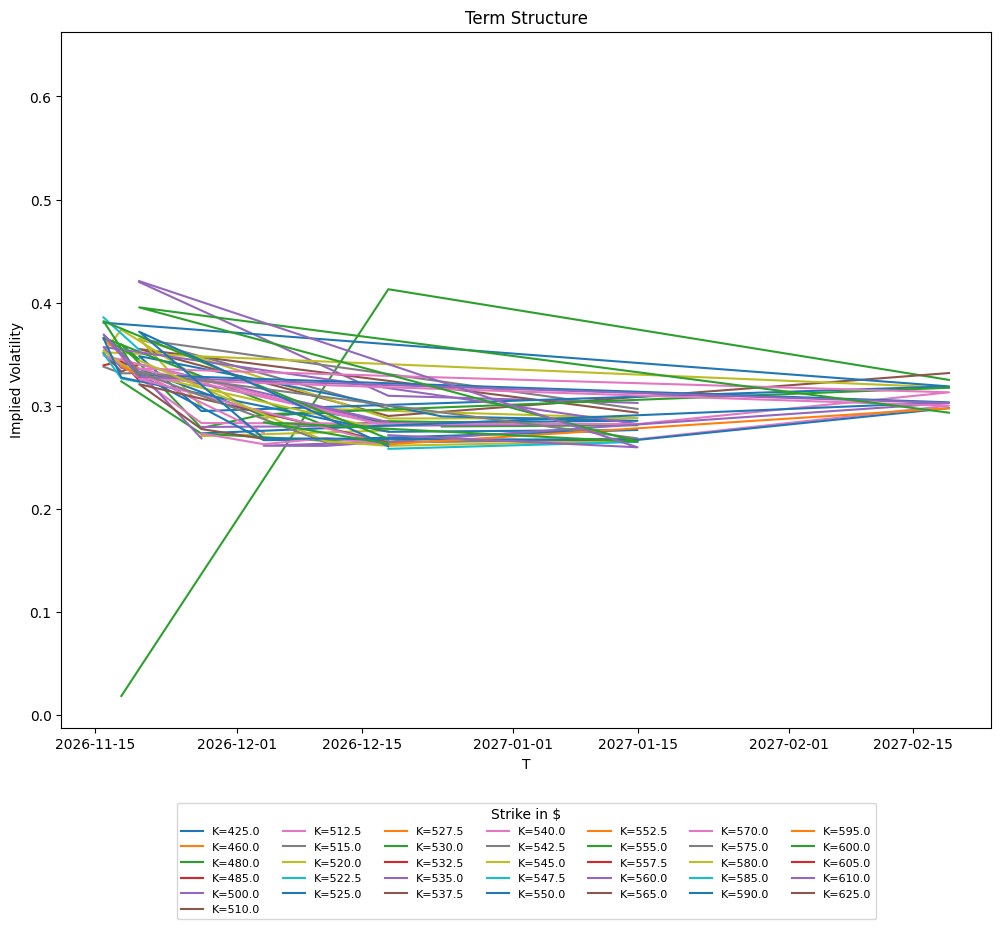

In [15]:
plt.figure(figsize=(12,12))
Ks_to_plot = np.arange(360,450,10) #[360.0, 370 ,380.0,390,400,410]
for K, data in term_structure.items():  # term_structure.items() renvoie couples (clé,valeur)
    plt.plot(data["T"],data["iv"],label=f"K={K}")

plt.xlabel("T")
plt.ylabel("Implied Volatility")
plt.title('Term Structure')

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=7,           
    title="Strike in $",
    fontsize=8,
    frameon=True
)

plt.subplots_adjust(bottom=0.30)

plt.show()

In [16]:
smile

{Timestamp('2026-11-16 00:00:00'): {'K': [520.0,
   522.5,
   525.0,
   527.5,
   530.0,
   532.5,
   535.0,
   537.5,
   540.0,
   542.5,
   545.0,
   547.5,
   550.0,
   555.0,
   560.0],
  'iv': [0.35191367795352296,
   0.3857078782644312,
   0.38058195231313213,
   0.3646694958729007,
   0.36613936172525685,
   0.33926714664202,
   0.3569776280210636,
   0.3510519489996423,
   0.3489003440983422,
   0.3378955693405124,
   0.3536383799017612,
   0.350561206783367,
   0.3654290313493461,
   0.38203208631616087,
   0.36914597310372665]},
 Timestamp('2026-11-18 00:00:00'): {'K': [480.0,
   520.0,
   525.0,
   527.5,
   530.0,
   532.5,
   535.0,
   537.5,
   540.0,
   542.5,
   545.0,
   547.5,
   550.0,
   552.5,
   555.0,
   557.5,
   560.0],
  'iv': [0.01865427129444258,
   0.3738069549625196,
   0.3423762336855223,
   0.3451692973269392,
   0.35940879156848543,
   0.34347621985331794,
   0.33667949961497246,
   0.333082065553078,
   0.33970940823617973,
   0.33152265393121744,
   0

In [17]:
rows = []

for date in smile:
    #print(smile[date]["K"])
    print(smile[date]["iv"])
    list_strike = smile[date]["K"]
    list_iv = smile[date]["iv"]
    for i in range(len(list_strike)):
        r = {"T":date,"K":list_strike[i],"IV":list_iv[i]}
        rows.append(r)

df_smile = pd.DataFrame(rows)



    
        
    
  


[0.35191367795352296, 0.3857078782644312, 0.38058195231313213, 0.3646694958729007, 0.36613936172525685, 0.33926714664202, 0.3569776280210636, 0.3510519489996423, 0.3489003440983422, 0.3378955693405124, 0.3536383799017612, 0.350561206783367, 0.3654290313493461, 0.38203208631616087, 0.36914597310372665]
[0.01865427129444258, 0.3738069549625196, 0.3423762336855223, 0.3451692973269392, 0.35940879156848543, 0.34347621985331794, 0.33667949961497246, 0.333082065553078, 0.33970940823617973, 0.33152265393121744, 0.3406752388452591, 0.3264908918809642, 0.3273992016971462, 0.3386058162690172, 0.32370705350129103, 0.3249641837939668, 0.35133706422943606]
[0.5560899243336649, 0.42002912833172024, 0.35506212054504277, 0.35155738377595913, 0.36451014903009804, 0.365294064080305, 0.35434777106036797, 0.34820960467721196, 0.33571445844120057, 0.3449992023202941, 0.32458342718222843, 0.34038867220385727, 0.3403375426887422, 0.33611975071589334, 0.3316608478489697, 0.33129637461726236, 0.3231991912226402

In [18]:
df_smile

,T,K,IV
0,2026-11-16,520.0,0.351914
1,2026-11-16,522.5,0.385708
2,2026-11-16,525.0,0.380582
3,2026-11-16,527.5,0.364669
4,2026-11-16,530.0,0.366139
...,...,...,...
142,2027-02-19,560.0,0.302654
143,2027-02-19,570.0,0.300116
144,2027-02-19,590.0,0.297745
145,2027-02-19,595.0,0.297620


In [21]:
# Computing time to maturity
df_smile["T"].dtype

valuation_date = pd.Timestamp.today().normalize() # today
print(valuation_date)

df_smile["Time to maturity in years"] = (df_smile["T"]-valuation_date).dt.total_seconds()/(365*24*3600)
df_smile


2026-11-13 00:00:00


,T,K,IV,Time to maturity in years
0,2026-11-16,520.0,0.351914,0.008219
1,2026-11-16,522.5,0.385708,0.008219
2,2026-11-16,525.0,0.380582,0.008219
3,2026-11-16,527.5,0.364669,0.008219
4,2026-11-16,530.0,0.366139,0.008219
...,...,...,...,...
142,2027-02-19,560.0,0.302654,0.268493
143,2027-02-19,570.0,0.300116,0.268493
144,2027-02-19,590.0,0.297745,0.268493
145,2027-02-19,595.0,0.297620,0.268493


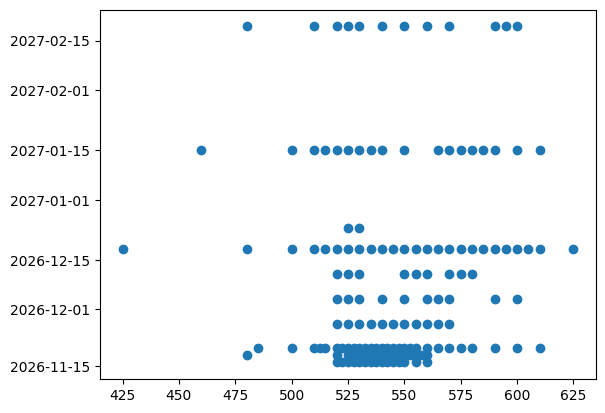

In [23]:
plt.plot(df_smile["K"],df_smile["T"],"o")

Text(0, 0.5, 'T')

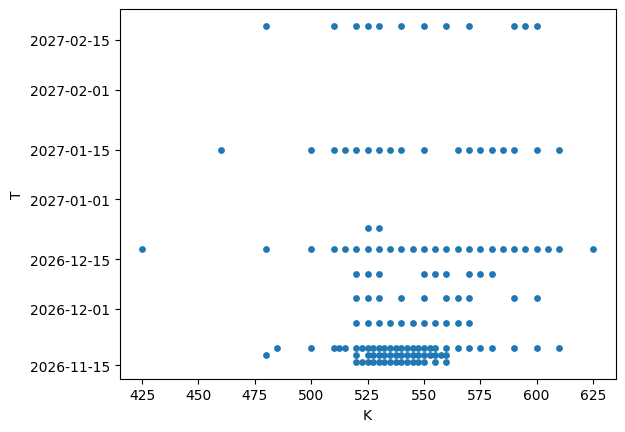

In [25]:
plt.scatter(df_smile["K"],df_smile["T"],s=15)
plt.xlabel("K")
plt.ylabel("T")

In [27]:
data_points = df_smile[["K","Time to maturity in years"]]
data_points

,K,Time to maturity in years
0,520.0,0.008219
1,522.5,0.008219
2,525.0,0.008219
3,527.5,0.008219
4,530.0,0.008219
...,...,...
142,560.0,0.268493
143,570.0,0.268493
144,590.0,0.268493
145,595.0,0.268493


In [ ]:
data_points = data_points.to_numpy()  # every row contains couple (K,T)
data_points

array([[5.20000000e+02, 8.21917808e-03],
       [5.22500000e+02, 8.21917808e-03],
       [5.25000000e+02, 8.21917808e-03],
       [5.27500000e+02, 8.21917808e-03],
       [5.30000000e+02, 8.21917808e-03],
       [5.32500000e+02, 8.21917808e-03],
       [5.35000000e+02, 8.21917808e-03],
       [5.37500000e+02, 8.21917808e-03],
       [5.40000000e+02, 8.21917808e-03],
       [5.42500000e+02, 8.21917808e-03],
       [5.45000000e+02, 8.21917808e-03],
       [5.47500000e+02, 8.21917808e-03],
       [5.50000000e+02, 8.21917808e-03],
       [5.55000000e+02, 8.21917808e-03],
       [5.60000000e+02, 8.21917808e-03],
       [4.80000000e+02, 1.36986301e-02],
       [5.20000000e+02, 1.36986301e-02],
       [5.25000000e+02, 1.36986301e-02],
       [5.27500000e+02, 1.36986301e-02],
       [5.30000000e+02, 1.36986301e-02],
       [5.32500000e+02, 1.36986301e-02],
       [5.35000000e+02, 1.36986301e-02],
       [5.37500000e+02, 1.36986301e-02],
       [5.40000000e+02, 1.36986301e-02],
       [5.425000

In [ ]:
from scipy.spatial import Delaunay

triangle = Delaunay(data_points)  # on calcule les triangles
print(triangle)

In [ ]:
triangle.simplices  # donne sommet triangle: ex [117,135,90]  117 correspond à indice de ligne de data_points

array([[117, 135,  90],
       [ 15, 117,  90],
       [146, 134, 114],
       [117,  91, 135],
       [ 91, 117,  15],
       [113,  59, 114],
       [134, 113, 114],
       [113, 112,  59],
       [112, 134, 146],
       [112, 113, 134],
       [ 32,  91,  15],
       [ 33,  32,  15],
       [ 32,  33,  92],
       [ 91,  32, 135],
       [ 32, 118, 135],
       [118,  32,  92],
       [118, 136, 135],
       [112,  58,  59],
       [  0,  33,  15],
       [ 34,  35,  93],
       [  0,  34,  33],
       [ 34,   0,  35],
       [119, 136, 118],
       [ 35, 119,  93],
       [136, 119,  35],
       [136, 120, 137],
       [120, 136,  35],
       [ 44, 125, 140],
       [139, 124, 140],
       [124,  44, 140],
       [ 44, 124,  98],
       [ 98, 124,  42],
       [124, 139,  42],
       [139, 138,  40],
       [142, 127, 143],
       [143, 127, 128],
       [130, 144, 143],
       [ 58, 110,  57],
       [120, 121, 137],
       [  0,  36,  35],
       [ 99, 125,  44],
       [100, 141

In [31]:
data_points[:,0] # on récupère les strike
data_points[:,1] # on récupère les T

array([0.00821918, 0.00821918, 0.00821918, 0.00821918, 0.00821918,
       0.00821918, 0.00821918, 0.00821918, 0.00821918, 0.00821918,
       0.00821918, 0.00821918, 0.00821918, 0.00821918, 0.00821918,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01917808, 0.01917808, 0.01917808,
       0.01917808, 0.01917808, 0.01917808, 0.01917808, 0.01917808,
       0.01917808, 0.01917808, 0.01917808, 0.01917808, 0.01917808,
       0.01917808, 0.01917808, 0.01917808, 0.01917808, 0.01917808,
       0.01917808, 0.01917808, 0.01917808, 0.01917808, 0.01917808,
       0.01917808, 0.01917808, 0.01917808, 0.01917808, 0.01917808,
       0.03835616, 0.03835616, 0.03835616, 0.03835616, 0.03835616,
       0.03835616, 0.03835616, 0.03835616, 0.03835616, 0.03835616,
       0.03835616, 0.05753425, 0.05753425, 0.05753425, 0.05753

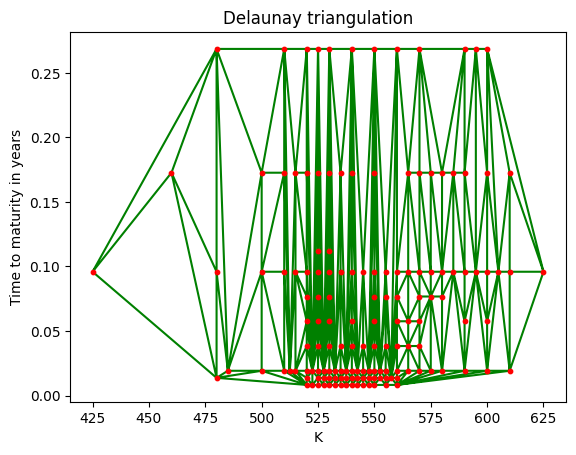

In [37]:
# Maillage

plt.triplot(
    data_points[:,0],
    data_points[:,1],
    triangle.simplices,
    color="green"
)

plt.scatter(data_points[:,0],data_points[:,1],s=10,color='red')

plt.xlabel("K")
plt.ylabel("Time to maturity in years")
plt.title("Delaunay triangulation")
plt.show()

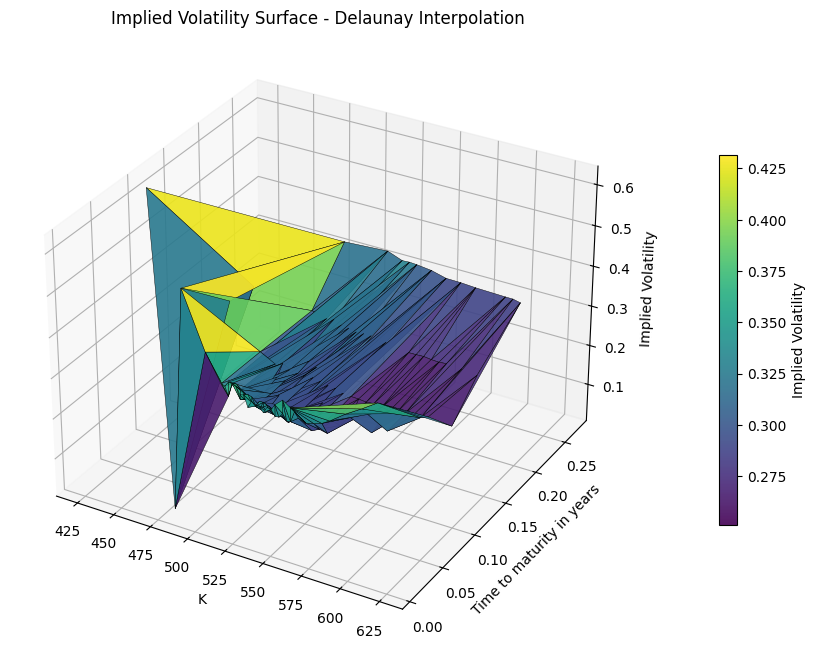

In [ ]:
# Building the surface


# Sommmets 
K = data_points[:,0]
T = data_points[:,1]
IV = df_smile["IV"].to_numpy()

# Création d'un graphique en 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

# On ajoute les triangles calculés précédemment
surface = ax.plot_trisurf(
    K,
    T,
    IV,
    triangles = triangle.simplices,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.9

)

ax.set_xlabel("K")
ax.set_ylabel("Time to maturity in years")
ax.set_zlabel("Implied Volatility")
ax.set_title("Implied Volatility Surface - Delaunay Interpolation")

fig.colorbar(
     surface,
    ax=ax,
    shrink=0.6,
    pad=0.1,
    label="Implied Volatility"
)

plt.show()


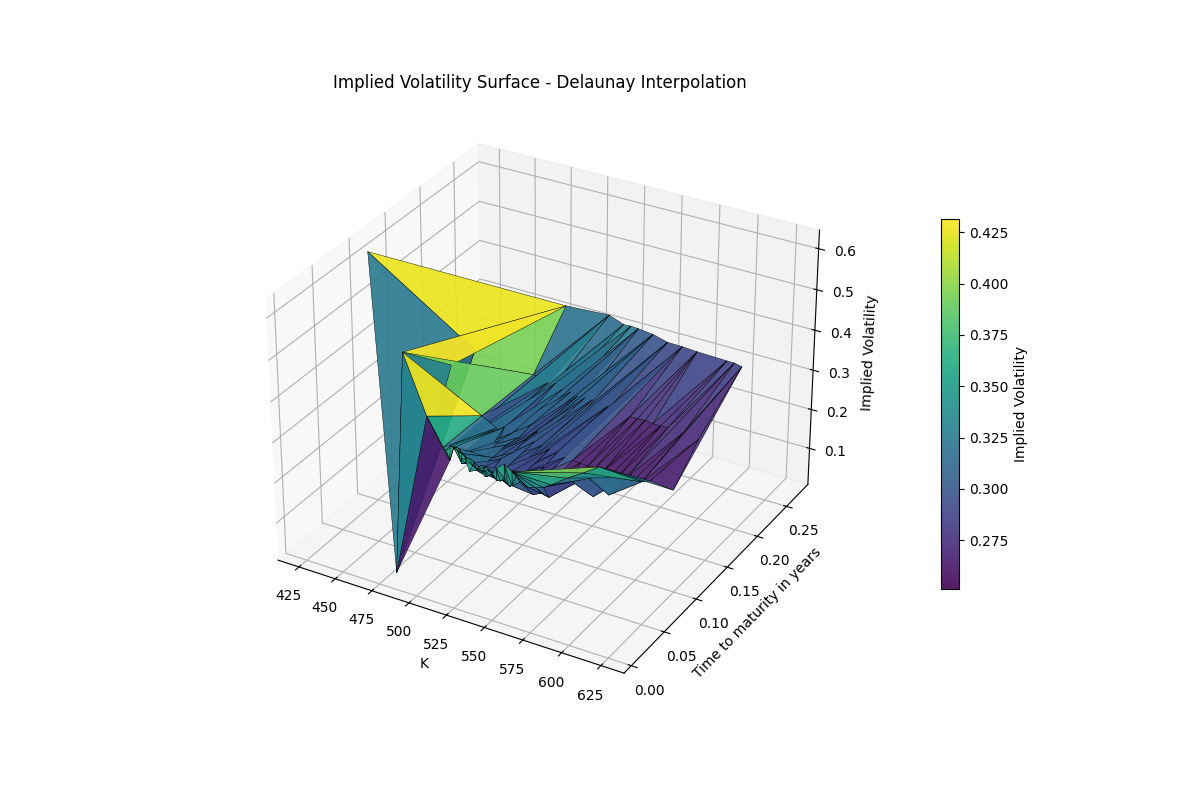

In [41]:
# Building the surface
# pour avoir surface interactive

%matplotlib widget  
# Sommmets 
K = data_points[:,0]
T = data_points[:,1]
IV = df_smile["IV"].to_numpy()

# Création d'un graphique en 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

# On ajoute les triangles calculés précédemment
surface = ax.plot_trisurf(
    K,
    T,
    IV,
    triangles = triangle.simplices,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.9

)

ax.set_xlabel("K")
ax.set_ylabel("Time to maturity in years")
ax.set_zlabel("Implied Volatility")
ax.set_title("Implied Volatility Surface - Delaunay Interpolation")

fig.colorbar(
     surface,
    ax=ax,
    shrink=0.6,
    pad=0.1,
    label="Implied Volatility"
)

plt.show()
